# Avance 3. Baseline
## Sistema de conteo de productos Vetlife — Equipo 32

**Fecha:** 18 de octubre de 2026
**Datos:** 44 fotografías de anaquel anotadas en Label Studio (polígonos por producto), 676 productos individuales
**Objetivo:** construir un modelo de referencia (*baseline*) que **identifique qué producto es cada caja** y, con ello, **cuente cuántas piezas de cada producto hay en una foto**. Establece las métricas de calidad y el piso contra el cual se evaluarán modelos más avanzados (CNN, detector + clasificador).

> **Qué cambió respecto al Avance 2.** El Avance 2 construyó descriptores *globales por fotografía* (brillo, entropía, relación de aspecto…) porque no había etiquetas; servían para auditar la calidad de las imágenes, pero no se relacionaban con identificar ni contar productos. En este avance ya hay anotaciones, así que las características se calculan **por objeto**: cada producto se recorta de la foto y se describe con su color, distribución de color, forma y textura. Cada fila de la tabla es *un producto con su etiqueta real*, que es exactamente la unidad que el sistema final debe reconocer.

## 1. Planteamiento y preguntas guía

El sistema final debe: (1) **localizar** cada caja en la foto y (2) **identificar** cuál de los productos es, para (3) **contar** por producto. Este avance se enfoca en la etapa (2) y en cómo se propaga al conteo (3); la etapa (1) se aborda con un modelo de detección en el siguiente avance.

| Pregunta del avance | Dónde se responde |
|---|---|
| ¿Qué algoritmo sirve como baseline? | §6 (regresión logística + referencias triviales y bosque aleatorio) |
| ¿Se puede medir la importancia de las características? | §9 (filtro, embebido, envoltura, permutación por grupos y PCA) |
| ¿Hay sub/sobreajuste? | §8 (train vs. prueba, validación cruzada por foto, curvas de aprendizaje y validación) |
| ¿Cuál es la métrica adecuada? | §5 (macro-F1 + error de conteo) |
| ¿Cuál debería ser el desempeño mínimo? | §11 |

## 2. Dependencias y carga de datos

Se usa Python, NumPy, pandas, Pillow, scikit-image, scikit-learn, Matplotlib y seaborn. El notebook busca localmente las fotografías (`label_data/`) y las exportaciones de Label Studio; **no se distribuyen en el repositorio** (las fotos pueden mostrar códigos de lote). Las imágenes que aparecen en las salidas están reducidas a baja resolución para ilustrar el caso de uso.

In [1]:
from pathlib import Path
import json, urllib.parse, time, platform, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display
from scipy.ndimage import laplace
from skimage.color import rgb2hsv
from skimage.feature import hog
from skimage.filters import sobel
from skimage.measure import shannon_entropy

import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, SelectFromModel, RFE, f_classif, mutual_info_classif
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, learning_curve, validation_curve
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, make_scorer, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 150)
SEED = 42
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.9.6 | numpy 2.0.2 | pandas 2.3.3 | scikit-learn 1.6.1


In [2]:
# Búsqueda de datos: funciona al ejecutar desde la raíz del proyecto, desde avances/ o desde Zproyect_Main/.
BASES = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
def find_dir(options):
    for base in BASES:
        for rel in options:
            if (base / rel).is_dir():
                return (base / rel).resolve()
    return None

PHOTO_DIR  = find_dir(["label_data", "Vetlife_Proyecto/label_data"])
EXPORT_DIR = find_dir(["Zproyect_Main/01_datos/exportaciones_label_studio", "01_datos/exportaciones_label_studio",
                       "Vetlife_Proyecto/Zproyect_Main/01_datos/exportaciones_label_studio"])
REF_DIR    = find_dir(["Zproyect_Main/Fotos_de_referencia", "Fotos_de_referencia", "Vetlife_Proyecto/Zproyect_Main/Fotos_de_referencia"])
if PHOTO_DIR is None or EXPORT_DIR is None:
    raise FileNotFoundError("Colocar label_data/ y las exportaciones de Label Studio junto al proyecto (ver README).")
print("Fotos anotadas  :", PHOTO_DIR.name, "| Exportaciones:", [p.name for p in sorted(EXPORT_DIR.iterdir()) if p.is_dir()])
print("Fotos de referencia:", REF_DIR.name if REF_DIR else "no disponibles")

Fotos anotadas  : label_data | Exportaciones: ['2026-10-15', '2026-10-17']
Fotos de referencia: Fotos_de_referencia


### 2.1 Imágenes de referencia: el escenario real

Estas fotografías sin anotar ilustran las condiciones en que se usará el sistema: anaqueles con muchas cajas casi idénticas, apiladas y con reflejos. Son el insumo que el modelo final debe contar.

9 fotografías de referencia


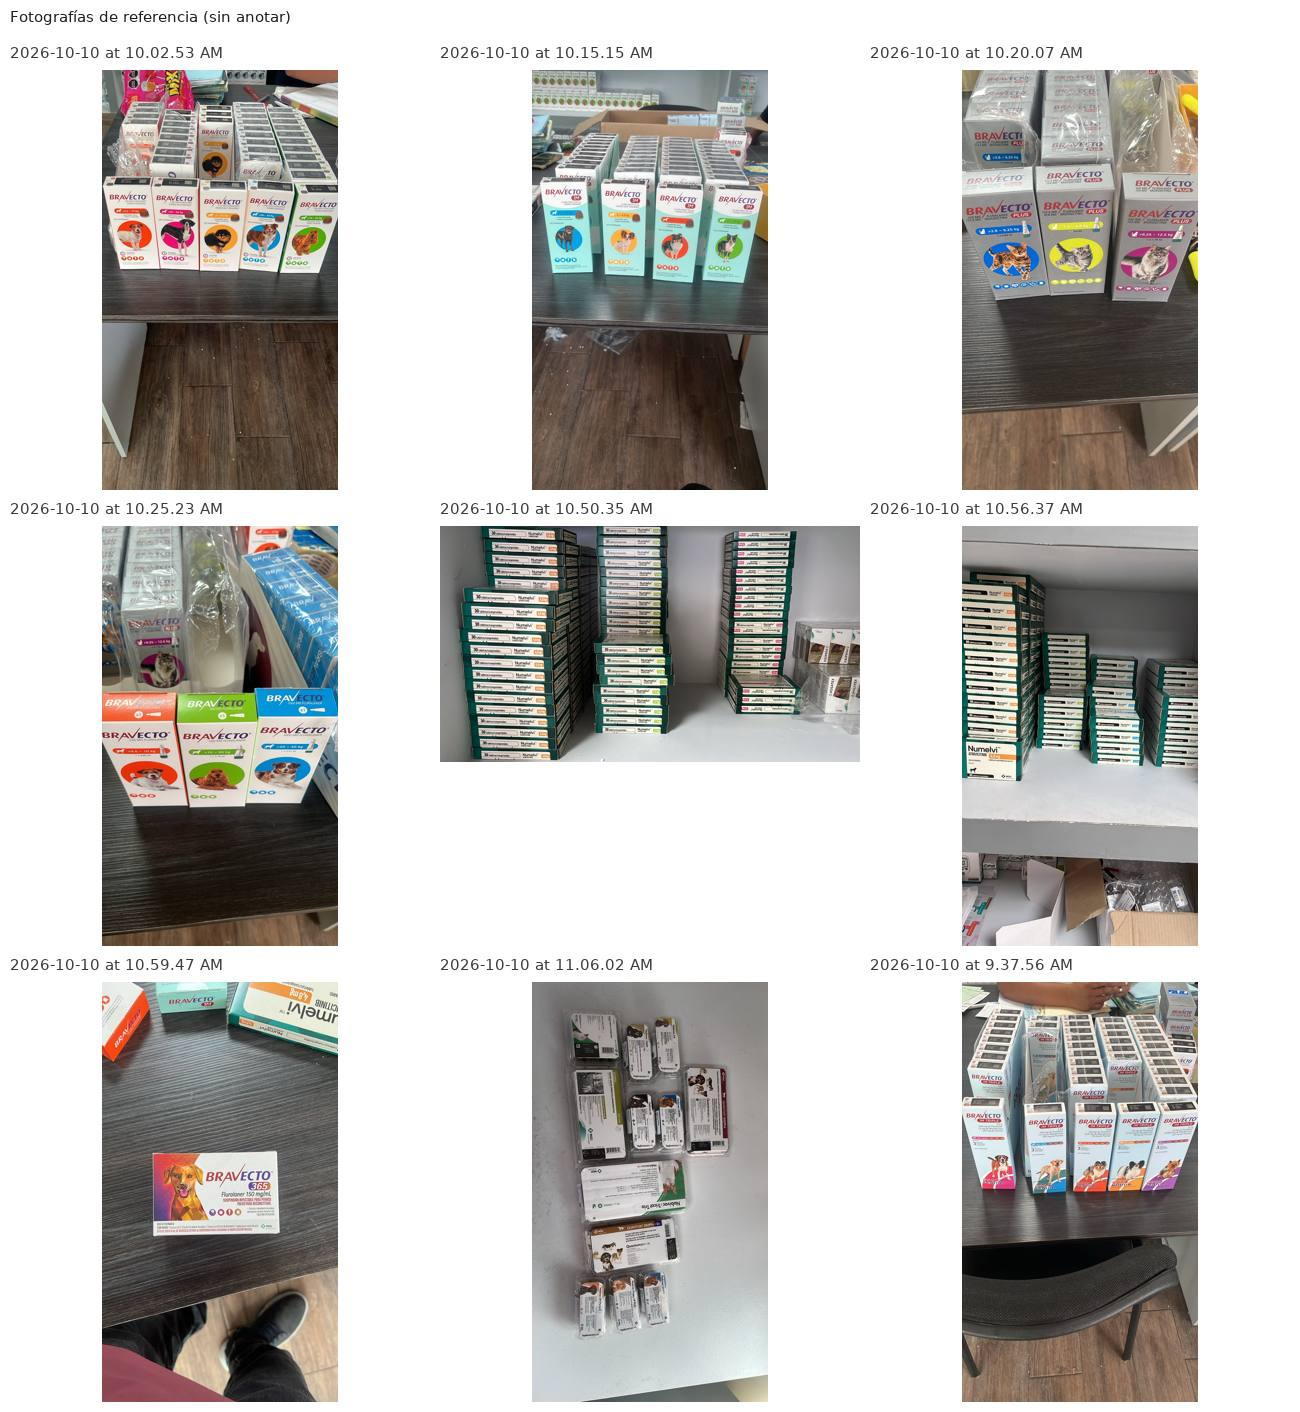

In [3]:
import io
from IPython.display import Image as IPyImage
from PIL import ImageFont
import matplotlib
try:   # DejaVu Sans (incluida con Matplotlib) trae acentos; la fuente por defecto de Pillow no siempre
    FONT = ImageFont.truetype(str(Path(matplotlib.get_data_path()) / "fonts" / "ttf" / "DejaVuSans.ttf"), 15)
except Exception:
    FONT = None

def show_mosaic(tiles, captions, cols=3, cell=420, title=None, quality=72):
    """Mosaico de imágenes como un solo JPEG de baja resolución (ilustra el escenario, no el detalle de la caja; pesa poco)."""
    rows, pad, head = (len(tiles) + cols - 1) // cols, 10, 26
    top = 34 if title else 0
    canvas = Image.new("RGB", (cols * (cell + pad) + pad, top + rows * (cell + head + pad) + pad), "white")
    d = ImageDraw.Draw(canvas)
    if title: d.text((pad, 8), title, fill=(30, 30, 30), font=FONT)
    for k, (im, cap) in enumerate(zip(tiles, captions)):
        im = im.copy(); im.thumbnail((cell, cell))
        x, y = pad + (k % cols) * (cell + pad), top + pad + (k // cols) * (cell + head + pad)
        d.text((x, y), cap, fill=(60, 60, 60), font=FONT)
        canvas.paste(im, (x + (cell - im.width) // 2, y + head))
    buf = io.BytesIO(); canvas.save(buf, "JPEG", quality=quality)
    display(IPyImage(data=buf.getvalue(), format="jpeg"))

def show_grid(paths, cols=3, max_side=420, title=None):
    tiles, caps = [], []
    for p in paths:
        with Image.open(p) as im:
            tiles.append(ImageOps.exif_transpose(im).convert("RGB"))
        caps.append(Path(p).stem.replace("WhatsApp Image ", ""))
    show_mosaic(tiles, caps, cols=cols, cell=max_side, title=title)

if REF_DIR:
    ref_paths = sorted(p for p in REF_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    print(f"{len(ref_paths)} fotografías de referencia")
    show_grid(ref_paths, cols=3, title="Fotografías de referencia (sin anotar)")

### 2.2 Lectura de anotaciones

Cada polígono de Label Studio marca un producto y su nombre exacto. Se leen todas las exportaciones de la carpeta (Equipo 32 reparte el etiquetado entre integrantes) y se agrupan por **fotografía**: los ids de tarea de Label Studio se repiten entre exportaciones, así que no se usan como llave. Se descartan polígonos duplicados exactos y los casi idénticos (IoU > 0.9 con la misma etiqueta).

In [4]:
def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def load_annotations(export_dir, photo_dir):
    index = {}
    for p in photo_dir.rglob("*"):
        if p.is_file(): index.setdefault(p.name.casefold(), []).append(p)
    photos, unresolved, ignored = {}, 0, 0
    for export in sorted(export_dir.rglob("*.json")):
        tasks = json.loads(export.read_text(encoding="utf-8-sig"))
        tasks = tasks.get("tasks", [tasks]) if isinstance(tasks, dict) else tasks
        for task in tasks:
            ref = str((task.get("data") or {}).get("image", "")).replace("\\", "/").replace("%5C", "/")
            rel = urllib.parse.parse_qs(urllib.parse.urlparse(ref).query).get("d", [urllib.parse.urlparse(ref).path])[0]
            matches = index.get(Path(urllib.parse.unquote(rel)).name.casefold(), [])
            if len(matches) != 1:
                unresolved += 1; continue
            entry = photos.setdefault(matches[0], {"polys": [], "seen": set()})
            for ann in task.get("annotations", []):
                if ann.get("was_cancelled"): continue
                for res in ann.get("result", []):
                    val = res.get("value") or {}
                    if res.get("type") != "polygonlabels" or not val.get("polygonlabels") or len(val.get("points", [])) < 3:
                        ignored += 1; continue
                    pts = [(float(x), float(y)) for x, y in val["points"]]
                    key = (val["polygonlabels"][0], tuple((round(x, 3), round(y, 3)) for x, y in pts))
                    if key in entry["seen"]: continue
                    entry["seen"].add(key)
                    entry["polys"].append((val["polygonlabels"][0].strip(), pts, int(res.get("image_rotation") or 0)))
    return photos, unresolved, ignored

photos, unresolved, ignored = load_annotations(EXPORT_DIR, PHOTO_DIR)
print(f"Fotos con anotaciones: {len(photos)} | tareas sin foto: {unresolved} | resultados ignorados (no polígonos): {ignored}")

Fotos con anotaciones: 44 | tareas sin foto: 0 | resultados ignorados (no polígonos): 1


## 3. Ingeniería de características por producto

Cada polígono se recorta de la foto (reducida a 1600 px de lado mayor) y se describe con **92 características** en seis grupos. Se calculan solo con los píxeles dentro del polígono para no mezclar el fondo del anaquel:

| Grupo | Qué mide | Por qué sirve para distinguir productos |
|---|---|---|
| Geometría (7) | tamaño relativo, proporción, posición, relleno del polígono | formato de caja/frasco y perspectiva de la toma |
| Color global (10) | medias y desviaciones de RGB, saturación y valor | color dominante de la marca |
| Matiz (12) | histograma de tono ponderado por saturación | paleta de color de cada línea (Bravecto, Nobivac…) |
| Distribución de color 3×3 (27) | color medio en una cuadrícula 3×3 | diseño del empaque (bandas, logotipos, zonas) |
| Textura (4) | densidad de bordes, Laplaciano, entropía | texto impreso y detalle del empaque |
| Formas HOG (32) | histograma de orientación de gradientes (2×2 celdas) | trazos y contornos gruesos |

Estas medidas **no leen el texto** de la caja (dosis, número de tabletas). Eso es deliberado: define el piso que cualquier modelo más sofisticado debe superar.

In [5]:
FEATURE_GROUPS = {"geo_": "Geometría", "col_": "Color global", "hue_": "Matiz", "lay_": "Distribución de color 3×3",
                  "tex_": "Textura", "hog_": "Formas (HOG)"}

def crop_features(img, pts_pct, W, H):
    poly = [(x * W / 100, y * H / 100) for x, y in pts_pct]
    xs, ys = zip(*poly)
    x1, y1, x2, y2 = max(0, int(min(xs))), max(0, int(min(ys))), min(W, int(np.ceil(max(xs)))), min(H, int(np.ceil(max(ys))))
    bw, bh = x2 - x1, y2 - y1
    if bw < 8 or bh < 8:
        return None, None
    crop = img.crop((x1, y1, x2, y2))
    m = Image.new("L", (bw, bh), 0); ImageDraw.Draw(m).polygon([(x - x1, y - y1) for x, y in poly], fill=1)
    mask = np.asarray(m, bool)
    if mask.sum() < 30:
        return None, None
    a = np.asarray(crop, np.float32) / 255; hsv = rgb2hsv(a)
    area = 0.5 * abs(sum(poly[i][0] * poly[(i + 1) % len(poly)][1] - poly[(i + 1) % len(poly)][0] * poly[i][1] for i in range(len(poly))))
    f = {"geo_ancho_rel": bw / W, "geo_alto_rel": bh / H, "geo_aspecto": bw / bh, "geo_area_rel": bw * bh / (W * H),
         "geo_cx": (x1 + x2) / 2 / W, "geo_cy": (y1 + y2) / 2 / H, "geo_relleno": min(1, area / (bw * bh))}
    px, hp = a[mask], hsv[mask]
    for i, c in enumerate("rgb"):
        f[f"col_{c}_media"] = px[:, i].mean(); f[f"col_{c}_std"] = px[:, i].std()
    f.update({"col_sat_media": hp[:, 1].mean(), "col_sat_std": hp[:, 1].std(), "col_val_media": hp[:, 2].mean(), "col_val_std": hp[:, 2].std()})
    hh, _ = np.histogram(hp[:, 0], bins=12, range=(0, 1), weights=hp[:, 1] + 1e-6); hh = hh / hh.sum()
    for i, v in enumerate(hh): f[f"hue_{i:02d}"] = v
    filled = np.where(mask[..., None], a, px.mean(0))
    small = np.asarray(Image.fromarray((filled * 255).astype(np.uint8)).resize((48, 48), Image.Resampling.BILINEAR), np.float32) / 255
    for r in range(3):
        for c in range(3):
            blk = small[r * 16:(r + 1) * 16, c * 16:(c + 1) * 16].mean((0, 1))
            for k, n in enumerate("rgb"): f[f"lay_{r}{c}_{n}"] = blk[k]
    g = small.mean(2); e = sobel(g)
    f.update({"tex_borde_media": e.mean(), "tex_borde_densidad": (e > 0.1).mean(), "tex_laplaciano_var": laplace(g).var(), "tex_entropia": shannon_entropy(g)})
    for i, v in enumerate(hog(g, orientations=8, pixels_per_cell=(24, 24), cells_per_block=(1, 1), feature_vector=True)):
        f[f"hog_{i:02d}"] = v
    thumb = crop.copy(); thumb.thumbnail((120, 120))
    return f, thumb

def linea(c):
    for prefix, name in [("Bravecto 1M Triple", "Bravecto 1M Triple"), ("Bravecto 1M", "Bravecto 1M"), ("Bravecto Spot", "Bravecto Spot On"),
                         ("Bravecto Plus", "Bravecto Plus gato"), ("Bravecto 365", "Bravecto 365"), ("Bravecto", "Bravecto por peso"),
                         ("Nobivac", "Nobivac"), ("Numelvi", "Numelvi"), ("Quantum", "Quantum Dog")]:
        if c.startswith(prefix): return name
    return "Otro"
marca = lambda c: c.split()[0].replace("NobivacFeline", "Nobivac")

t0 = time.time()
rows, THUMBS, POLYS = [], [], []
PHOTO_PATH = {}
for path, entry in sorted(photos.items(), key=lambda kv: str(kv[0]).casefold()):
    with Image.open(path) as src:
        img = ImageOps.exif_transpose(src).convert("RGB")
    img.thumbnail((1600, 1600)); W, H = img.size
    PHOTO_PATH[path.name] = path
    kept = []
    for label, pts, rotation in entry["polys"]:
        if rotation != 0: continue
        xs, ys = [p[0] for p in pts], [p[1] for p in pts]; box = [min(xs), min(ys), max(xs), max(ys)]
        if any(l == label and box_iou(b, box) > 0.9 for l, b in kept): continue
        f, thumb = crop_features(img, pts, W, H)
        if f is None: continue
        kept.append((label, box))
        rows.append({"foto": path.name, "clase": label, "linea": linea(label), "marca": marca(label), **f}); THUMBS.append(thumb); POLYS.append(pts)
df = pd.DataFrame(rows)
FEATURES = [c for c in df.columns if c.startswith(tuple(FEATURE_GROUPS))]
GROUP_OF = {c: next(v for k, v in FEATURE_GROUPS.items() if c.startswith(k)) for c in FEATURES}
print(f"Productos (filas): {len(df)} | fotos: {df.foto.nunique()} | clases: {df.clase.nunique()} | características: {len(FEATURES)} | {time.time() - t0:.0f} s")
print("Valores faltantes:", int(df[FEATURES].isna().sum().sum()), "| infinitos:", int(np.isinf(df[FEATURES].values).sum()))
display(pd.Series(Counter(GROUP_OF.values())).rename("n_características").to_frame())

Productos (filas): 676 | fotos: 44 | clases: 44 | características: 92 | 30 s
Valores faltantes: 0 | infinitos: 0


,n_características
Geometría,7
Color global,10
Matiz,12
Distribución de color 3×3,27
Textura,4
Formas (HOG),32


### 3.1 Los datos: desbalance y similitud entre productos

El catálogo tiene muchas presentaciones casi idénticas que difieren en la dosis o el número de tabletas, y las fotos de anaquel tienen muchas copias del mismo producto. Los dos factores condicionan la elección de métrica y del esquema de validación.

Clases: 44 | productos por clase: mediana 12, mínimo 1, máximo 62
Clases con menos de 5 ejemplos: 9 | con 1 ejemplo: 1
La clase mayoritaria concentra 9.2% de los productos (referencia para 'accuracy' ingenua)
Productos por foto: mediana 7, mínimo 1, máximo 60


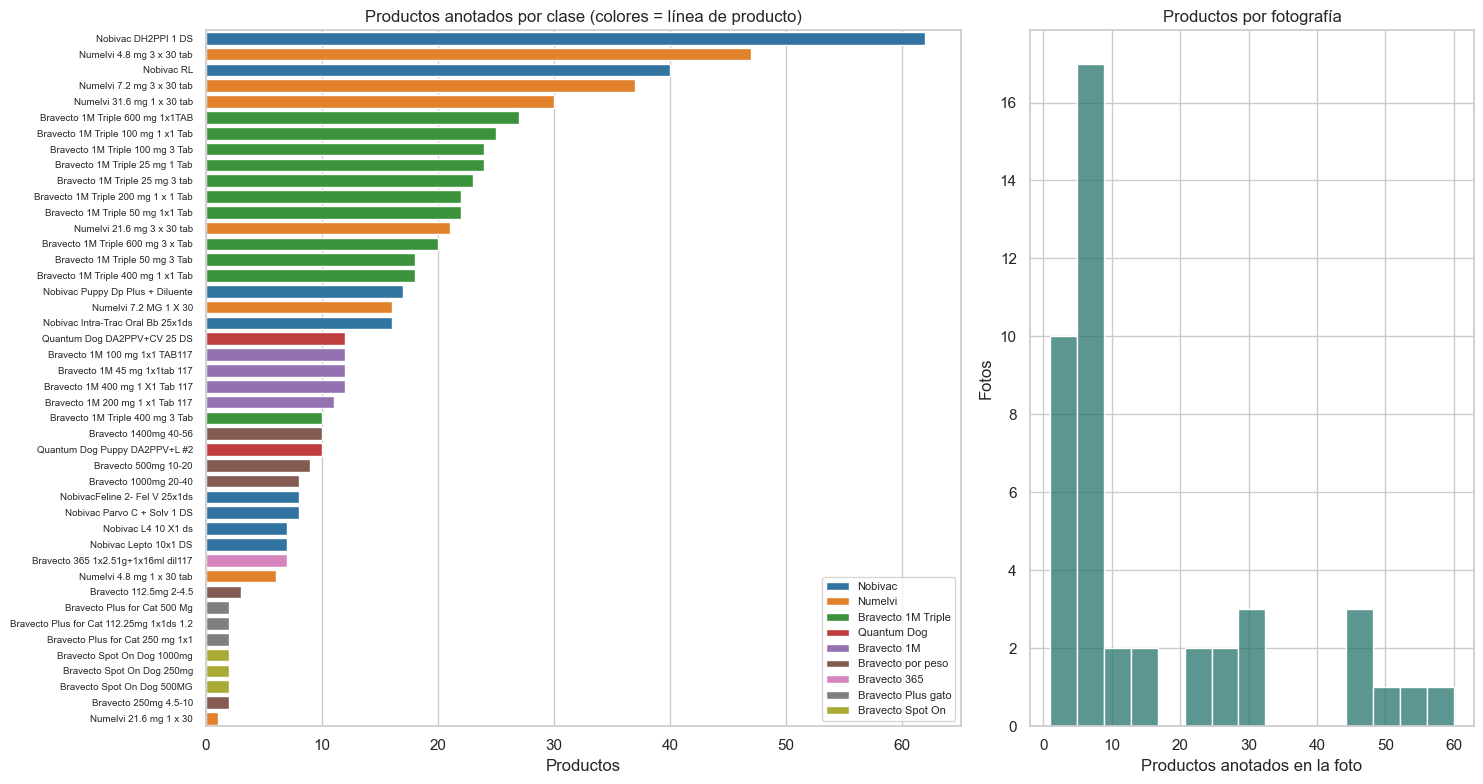

In [6]:
counts = df.clase.value_counts()
print(f"Clases: {len(counts)} | productos por clase: mediana {counts.median():.0f}, mínimo {counts.min()}, máximo {counts.max()}")
print(f"Clases con menos de 5 ejemplos: {(counts < 5).sum()} | con 1 ejemplo: {(counts == 1).sum()}")
print(f"La clase mayoritaria concentra {counts.iloc[0] / len(df):.1%} de los productos (referencia para 'accuracy' ingenua)")
per_photo = df.groupby("foto").size()
print(f"Productos por foto: mediana {per_photo.median():.0f}, mínimo {per_photo.min()}, máximo {per_photo.max()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1.7, 1]})
order = counts.index
sns.barplot(y=order, x=counts.values, hue=[linea(c) for c in order], dodge=False, ax=axes[0], palette="tab10")
axes[0].set_title("Productos anotados por clase (colores = línea de producto)"); axes[0].set_xlabel("Productos"); axes[0].set_ylabel("")
axes[0].tick_params(axis="y", labelsize=7); axes[0].legend(fontsize=8, loc="lower right")
sns.histplot(per_photo.values, bins=15, color="#26736b", ax=axes[1])
axes[1].set_title("Productos por fotografía"); axes[1].set_xlabel("Productos anotados en la foto"); axes[1].set_ylabel("Fotos")
fig.tight_layout(); plt.show()

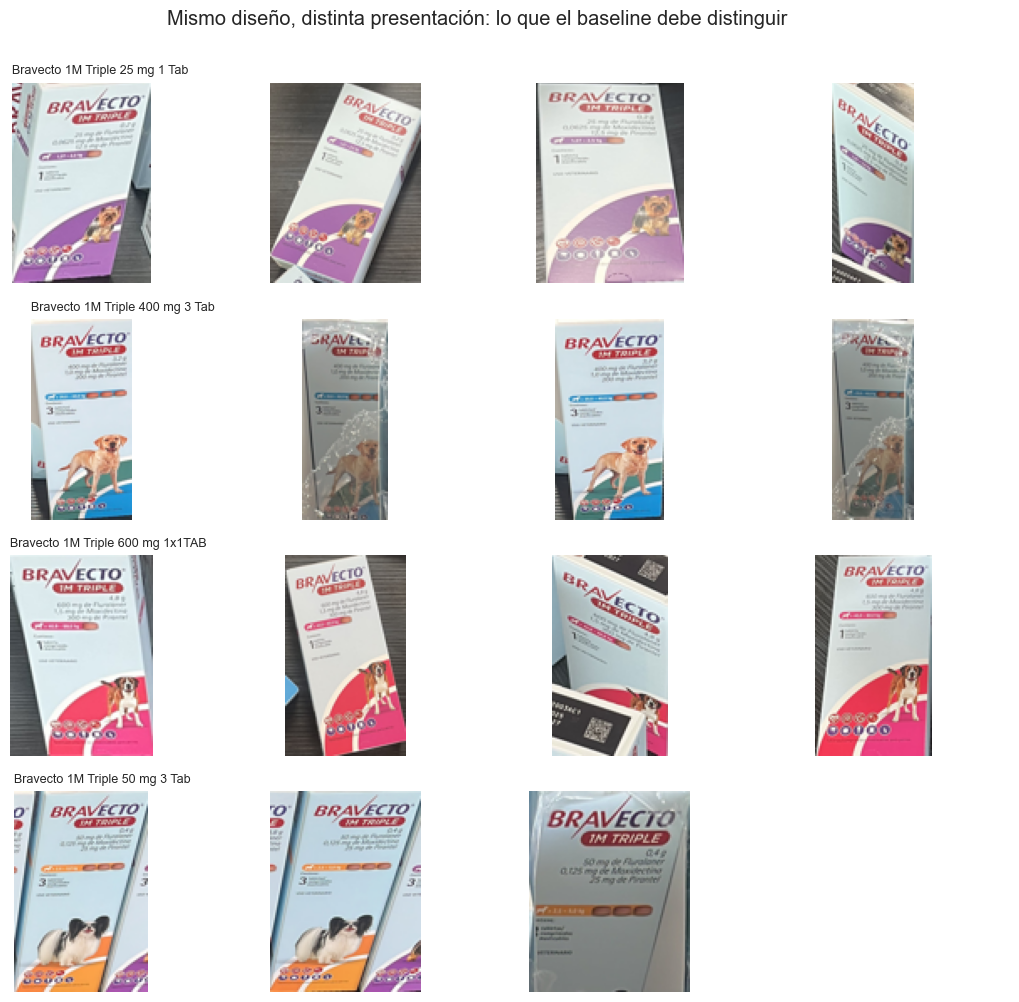

In [7]:
# Cómo se ven los recortes: 4 presentaciones de la misma línea, que difieren solo en dosis / número de tabletas.
# Se muestran frentes de caja (más altas que anchas); las tapas laterales se analizan en la sección 7.1.
front = df.geo_aspecto < 0.8
triple = df[(df.linea == "Bravecto 1M Triple") & front].clase.value_counts()
show_classes = triple[triple >= 3].index[:4].tolist()
fig, axes = plt.subplots(len(show_classes), 4, figsize=(11, 2.5 * len(show_classes)))
for r, cls in enumerate(show_classes):
    idxs = df.index[(df.clase == cls) & front].tolist()[:: max(1, ((df.clase == cls) & front).sum() // 4)][:4]
    for c in range(4):
        ax = axes[r, c]; ax.axis("off")
        if c < len(idxs): ax.imshow(THUMBS[idxs[c]])
        if c == 0: ax.set_title(cls, fontsize=9, loc="left")
fig.suptitle("Mismo diseño, distinta presentación: lo que el baseline debe distinguir", y=1.0)
fig.tight_layout(); plt.show()

## 4. Partición entrenamiento / prueba

**Se particiona por fotografía, no por producto.** Los productos de una misma foto comparten luz, ángulo y fondo (y a veces son copias de la misma caja); si unos cayeran en entrenamiento y otros en prueba, la prueba sería artificialmente fácil (*fuga de información*). Se usa `StratifiedGroupKFold` (grupo = foto, estratificado por clase): el primer pliegue de 5 es el conjunto de prueba (~20 %) y los 4 restantes son entrenamiento, con una semilla fija. La lista de fotos de prueba se exporta para que los modelos futuros se evalúen exactamente con los mismos datos.

In [8]:
X = df[FEATURES].values; y = df.clase.values; groups = df.foto.values
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
Xtr, ytr, gtr = X[train_idx], y[train_idx], groups[train_idx]
Xte, yte, gte = X[test_idx], y[test_idx], groups[test_idx]
assert not set(gtr) & set(gte), "una foto no puede estar en ambos conjuntos"

unseen = sorted(set(yte) - set(ytr))
print(f"Entrenamiento: {len(train_idx)} productos / {len(set(gtr))} fotos / {len(set(ytr))} clases")
print(f"Prueba       : {len(test_idx)} productos / {len(set(gte))} fotos / {len(set(yte))} clases")
print(f"Clases de prueba que NO aparecen en entrenamiento: {len(unseen)} {unseen}")
print("(Ningún modelo puede acertarlas; se conservan en la evaluación porque en producción también pueden aparecer productos poco vistos.)")

split_dir = (EXPORT_DIR.parent)
pd.Series(sorted(set(gte)), name="foto_prueba").to_csv(split_dir / "avance3_fotos_prueba.csv", index=False)
print("Fotos de prueba exportadas a:", (split_dir / "avance3_fotos_prueba.csv").name)

cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)   # validación cruzada interna, solo con entrenamiento

Entrenamiento: 515 productos / 34 fotos / 41 clases
Prueba       : 161 productos / 10 fotos / 27 clases
Clases de prueba que NO aparecen en entrenamiento: 3 ['Bravecto 112.5mg 2-4.5', 'Bravecto 250mg 4.5-10', 'Bravecto 500mg 10-20']
(Ningún modelo puede acertarlas; se conservan en la evaluación porque en producción también pueden aparecer productos poco vistos.)
Fotos de prueba exportadas a: avance3_fotos_prueba.csv


## 5. Métrica

**Métrica principal: macro-F1 sobre las clases presentes en la prueba.** Se justifica por el problema de negocio y por los datos:

1. **Desbalance.** Una clase concentra ~9 % de los productos y varias tienen 1–3 ejemplos. La *accuracy* premia al modelo que acierta lo frecuente; un inventario necesita **cada** producto bien identificado. El macro-F1 promedia el F1 de cada clase con el mismo peso (combina precisión y recall).
2. **Costo del error.** Confundir dos dosis del mismo antiparasitario no es un error menor: el conteo por producto queda mal y, en una clínica, la presentación equivocada tiene consecuencias. Por eso se mide también la exactitud **a nivel línea de producto** (¿al menos se identificó la familia correcta?) para separar errores "cercanos" de errores graves.
3. **Cercanía con el conteo.** El objetivo del sistema es contar. Se agrega una **métrica de negocio**: el error absoluto medio del conteo por foto y producto (§10).

Métricas complementarias: *accuracy*, *balanced accuracy* (recall promedio por clase), *top-3 accuracy* (¿la clase real está entre las 3 mejores sugerencias?; útil si un operador confirma) y exactitud por línea. El macro-F1 se calcula solo sobre clases presentes en la verdad de terreno para no penalizar dos veces la sobre-predicción.

In [9]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0)
macro_f1_scorer = make_scorer(macro_f1)

def top3_accuracy(model, X_, y_):
    proba = model.predict_proba(X_)
    top = model.classes_[np.argsort(-proba, axis=1)[:, :3]]
    return float(np.mean([t in row for t, row in zip(y_, top)]))

def evaluate(model, X_, y_):
    pred = model.predict(X_)
    return {"macro_f1": macro_f1(y_, pred), "accuracy": accuracy_score(y_, pred), "balanced_acc": balanced_accuracy_score(y_, pred),
            "top3_acc": top3_accuracy(model, X_, y_), "acc_linea": np.mean([linea(a) == linea(b) for a, b in zip(y_, pred)]), "acc_marca": np.mean([marca(a) == marca(b) for a, b in zip(y_, pred)])}, pred

## 6. Algoritmo baseline

**Tipo de problema:** clasificación multiclase (44 productos) de datos tabulares derivados de imágenes (datos no estructurados convertidos a 92 variables numéricas), con pocos ejemplos (676) y fuerte desbalance.

| Candidato | Papel | Por qué |
|---|---|---|
| `DummyClassifier` (mayoritaria y estratificado) | **Piso**: lo que se obtiene sin aprender nada | Si el modelo real no los supera, los datos no contienen señal útil. |
| **Regresión logística multinomial** (estandarizada, `class_weight='balanced'`, regularizada con C) | **Baseline principal** | Es el punto de partida estándar en clasificación (Géron, 2022, cap. 4): rápida, bien entendida y **interpretable** (coeficientes por clase). Con 676 filas y 92 variables regularizar es indispensable y la regresión logística lo permite de forma directa. `class_weight='balanced'` compensa el desbalance. |
| Bosque aleatorio (300 árboles, `class_weight='balanced_subsample'`) | Comparación no lineal | Captura interacciones sin escalar, no necesita supuestos de linealidad y entrega importancias de características (embebidas) para §9. |

**Por qué no una CNN todavía.** Una red convolucional preentrenada será el siguiente paso, pero un baseline debe ser simple, rápido y explicable para que sus resultados sirvan como referencia honesta. Con unos 15 ejemplos por clase en promedio, una CNN entrenada desde cero sobreajustaría; con transfer learning probablemente supere a este baseline, y este avance deja medido por cuánto.

### 6.1 Selección del hiperparámetro C (solo con entrenamiento)

,C,macroF1_entrenamiento,macroF1_validacion,desv_validacion
0,0.003,0.571,0.211,0.018
1,0.010,0.730,0.238,0.033
2,0.030,0.865,0.260,0.022
3,0.100,0.951,0.316,0.022
4,0.300,0.981,0.338,0.034
5,1.000,0.997,0.343,0.044
6,10.000,1.000,0.348,0.016
7,100.000,1.000,0.355,0.024


Mejor macro-F1 de validación: 0.355 (C=100.0) | C elegido por la regla de un error estándar: 0.3


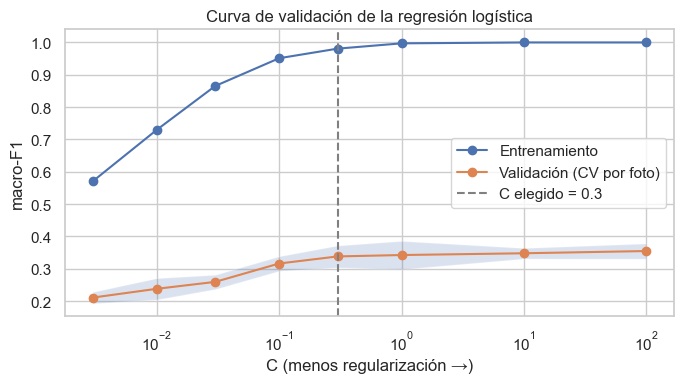

In [10]:
c_range = [0.003, 0.01, 0.03, 0.1, 0.3, 1, 10, 100]
tr_scores, va_scores = validation_curve(make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000)),
                                        Xtr, ytr, groups=gtr, param_name="logisticregression__C", param_range=c_range,
                                        cv=cv, scoring=macro_f1_scorer)
vc = pd.DataFrame({"C": c_range, "macroF1_entrenamiento": tr_scores.mean(1), "macroF1_validacion": va_scores.mean(1), "desv_validacion": va_scores.std(1)})
display(vc.round(3))
# Regla de "un error estándar": entre los C cuyo macro-F1 de validación está a una desviación del mejor, se elige el más regularizado
# (modelo más simple con desempeño equivalente). Evita quedarse en el borde de la rejilla cuando la curva es plana.
i_best = vc.macroF1_validacion.idxmax()
BEST_C = float(vc[vc.macroF1_validacion >= vc.loc[i_best, "macroF1_validacion"] - vc.loc[i_best, "desv_validacion"]].C.min())
print(f"Mejor macro-F1 de validación: {vc.loc[i_best, 'macroF1_validacion']:.3f} (C={vc.loc[i_best, 'C']}) | C elegido por la regla de un error estándar: {BEST_C}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(c_range, tr_scores.mean(1), "o-", label="Entrenamiento"); ax.semilogx(c_range, va_scores.mean(1), "o-", label="Validación (CV por foto)")
ax.fill_between(c_range, va_scores.mean(1) - va_scores.std(1), va_scores.mean(1) + va_scores.std(1), alpha=0.2)
ax.axvline(BEST_C, ls="--", color="gray", label=f"C elegido = {BEST_C}"); ax.set_xlabel("C (menos regularización →)"); ax.set_ylabel("macro-F1")
ax.set_title("Curva de validación de la regresión logística"); ax.legend(); fig.tight_layout(); plt.show()

In [11]:
def make_lr(C=BEST_C): return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=3000))
def make_rf(): return RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)

models = {"Dummy · clase mayoritaria": DummyClassifier(strategy="most_frequent"),
          "Dummy · estratificado (azar)": DummyClassifier(strategy="stratified", random_state=SEED),
          "Regresión logística (baseline)": make_lr(),
          "Bosque aleatorio": make_rf()}
results, preds = [], {}
for name, model in models.items():
    model.fit(Xtr, ytr)
    m_tr, _ = evaluate(model, Xtr, ytr); m_te, preds[name] = evaluate(model, Xte, yte)
    results.append({"modelo": name, **{f"{k}_train": v for k, v in m_tr.items() if k in ("macro_f1", "accuracy")},
                    **{f"{k}_test": v for k, v in m_te.items()}})
res = pd.DataFrame(results).set_index("modelo")
display(res.round(3))

,macro_f1_train,accuracy_train,macro_f1_test,accuracy_test,balanced_acc_test,top3_acc_test,acc_linea_test,acc_marca_test
modelo,,,,,,,,
Dummy · clase mayoritaria,0.004,0.089,0.000,0.006,0.037,0.050,0.019,0.019
Dummy · estratificado (azar),0.022,0.045,0.007,0.006,0.005,0.056,0.180,0.373
Regresión logística (baseline),0.974,0.973,0.169,0.255,0.173,0.404,0.565,0.913
Bosque aleatorio,1.000,1.000,0.173,0.242,0.213,0.429,0.596,0.739


## 7. Resultados en prueba

Azar estratificado (200 semillas): macro-F1 = 0.017 ± 0.011 | accuracy = 0.024
Azar uniforme teórico: accuracy = 1/41 = 0.024
Accuracy sobre productos de clases vistas en entrenamiento: 0.279 (147 de 161 productos de prueba); los 14 restantes pertenecen a clases nunca vistas y no pueden acertarse.


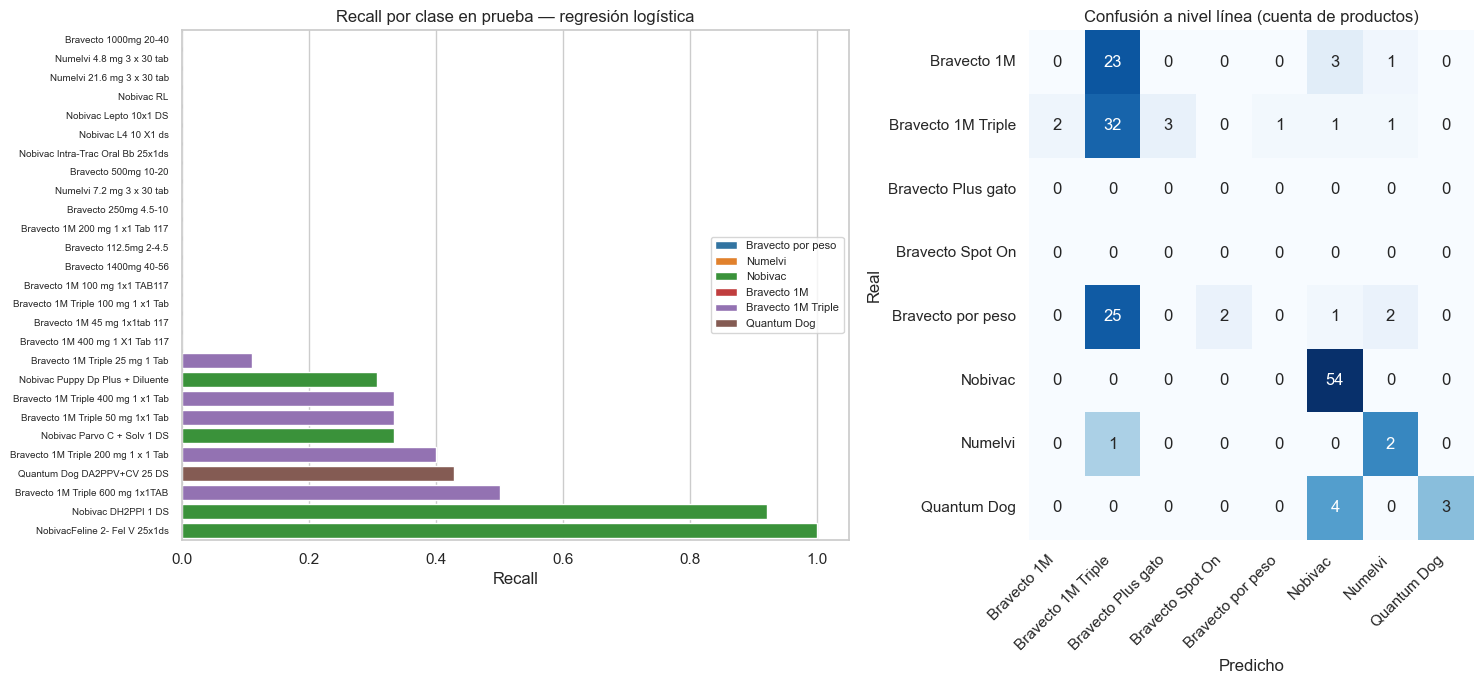

Errores: 120 de 161 | 41.7% de los errores caen dentro de la misma línea de producto


,,veces
real,predicho,
Nobivac Intra-Trac Oral Bb 25x1ds,Nobivac RL,9
Bravecto 500mg 10-20,Bravecto 1M Triple 200 mg 1 x 1 Tab,9
Bravecto 1M 45 mg 1x1tab 117,Bravecto 1M Triple 400 mg 3 Tab,7
Bravecto 1M 200 mg 1 x1 Tab 117,Bravecto 1M Triple 200 mg 1 x 1 Tab,5
Bravecto 1M 400 mg 1 X1 Tab 117,Bravecto 1M Triple 400 mg 3 Tab,5
Bravecto 1000mg 20-40,Bravecto 1M Triple 200 mg 1 x 1 Tab,4
Nobivac Puppy Dp Plus + Diluente,Nobivac RL,4
Bravecto 1M Triple 100 mg 1 x1 Tab,Bravecto 1M Triple 50 mg 1x1 Tab,4
Quantum Dog DA2PPV+CV 25 DS,Nobivac RL,4


In [12]:
# Azar "justo": el DummyClassifier estratificado depende de la semilla; se promedia en 200 semillas.
rand_f1 = [macro_f1(yte, DummyClassifier(strategy="stratified", random_state=s).fit(Xtr, ytr).predict(Xte)) for s in range(200)]
rand_acc = [accuracy_score(yte, DummyClassifier(strategy="stratified", random_state=s).fit(Xtr, ytr).predict(Xte)) for s in range(200)]
print(f"Azar estratificado (200 semillas): macro-F1 = {np.mean(rand_f1):.3f} ± {np.std(rand_f1):.3f} | accuracy = {np.mean(rand_acc):.3f}")
print(f"Azar uniforme teórico: accuracy = 1/{len(set(ytr))} = {1 / len(set(ytr)):.3f}")

best = preds["Regresión logística (baseline)"]
seen = np.isin(yte, ytr)
print(f"Accuracy sobre productos de clases vistas en entrenamiento: {accuracy_score(yte[seen], best[seen]):.3f} ({seen.sum()} de {len(yte)} productos de prueba); "
      f"los {(~seen).sum()} restantes pertenecen a clases nunca vistas y no pueden acertarse.")
by_class = pd.DataFrame({"real": yte, "pred": best}).assign(ok=lambda d: d.real == d.pred).groupby("real").agg(productos=("ok", "size"), aciertos=("ok", "sum"))
by_class["recall"] = by_class.aciertos / by_class.productos
by_class["linea"] = [linea(c) for c in by_class.index]
by_class = by_class.sort_values("recall")

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.5, 1]})
sns.barplot(y=by_class.index, x=by_class.recall, hue=by_class.linea, dodge=False, ax=axes[0], palette="tab10")
axes[0].set_title("Recall por clase en prueba — regresión logística"); axes[0].set_xlabel("Recall"); axes[0].set_ylabel("")
axes[0].tick_params(axis="y", labelsize=7); axes[0].legend(fontsize=8, loc="center right")

lines = sorted(set(map(linea, yte)) | set(map(linea, best)))
cm = confusion_matrix([linea(c) for c in yte], [linea(c) for c in best], labels=lines)
sns.heatmap(cm / cm.sum(1, keepdims=True).clip(1), annot=cm, fmt="d", cmap="Blues", xticklabels=lines, yticklabels=lines, ax=axes[1], cbar=False)
axes[1].set_title("Confusión a nivel línea (cuenta de productos)"); axes[1].set_xlabel("Predicho"); axes[1].set_ylabel("Real")
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right"); fig.tight_layout(); plt.show()

conf = pd.DataFrame({"real": yte, "predicho": best}); conf = conf[conf.real != conf.predicho]
conf["misma_linea"] = [linea(a) == linea(b) for a, b in zip(conf.real, conf.predicho)]
print(f"Errores: {len(conf)} de {len(yte)} | {conf.misma_linea.mean():.1%} de los errores caen dentro de la misma línea de producto")
display(conf.groupby(["real", "predicho"]).size().sort_values(ascending=False).head(10).rename("veces").to_frame())

### 7.1 ¿Dónde falla el baseline? (caso de uso)

Dos preguntas útiles para el diseño del sistema: ¿se identifica al menos la **marca**? y ¿importa **qué cara** de la caja se anotó? En una pila de cajas casi solo se ve la tapa o el lateral (un panel con lote y caducidad), que **no distingue la dosis**, mientras que el frente sí muestra el nombre. Se usan predicciones fuera de muestra (validación cruzada por foto, todos los productos) para tener más casos que los 161 de la prueba.

,productos,producto_exacto,linea,marca
cara,,,,
vertical (frente de caja),87,0.506,0.782,0.943
intermedia,137,0.343,0.642,0.796
horizontal (tapa/lateral),452,0.438,0.825,0.960


Nivel de identificación (validación cruzada, todos los productos): marca 92.5% · línea 78.3% · producto exacto 42.8%


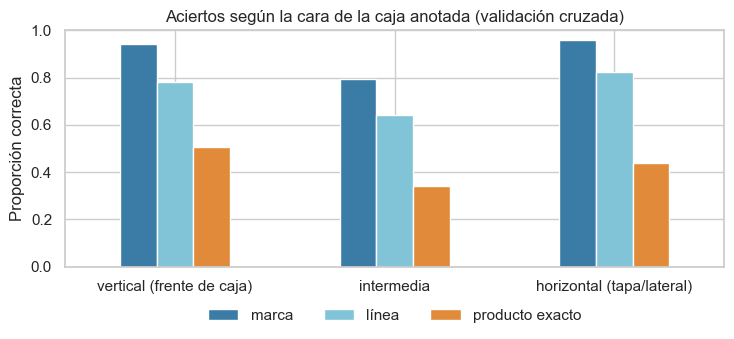

In [13]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(make_lr(), X, y, groups=groups, cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1))
cara = pd.cut(df.geo_aspecto, [0, 0.8, 2.0, 100], labels=["vertical (frente de caja)", "intermedia", "horizontal (tapa/lateral)"])
where = pd.DataFrame({"cara": cara, "ok_producto": oof == y, "ok_linea": [linea(a) == linea(b) for a, b in zip(y, oof)], "ok_marca": [marca(a) == marca(b) for a, b in zip(y, oof)]})
resumen_cara = where.groupby("cara").agg(productos=("ok_producto", "size"), producto_exacto=("ok_producto", "mean"), linea=("ok_linea", "mean"), marca=("ok_marca", "mean"))
display(resumen_cara.round(3))
print(f"Nivel de identificación (validación cruzada, todos los productos): marca {where.ok_marca.mean():.1%} · línea {where.ok_linea.mean():.1%} · producto exacto {where.ok_producto.mean():.1%}")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
resumen_cara[["marca", "linea", "producto_exacto"]].plot.bar(ax=ax, color=["#3a7ca5", "#81c3d7", "#e08a3a"], rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("Proporción correcta"); ax.set_xlabel(""); ax.set_title("Aciertos según la cara de la caja anotada (validación cruzada)"); ax.legend(["marca", "línea", "producto exacto"], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
fig.tight_layout(); plt.show()

## 8. ¿Hay sub o sobreajuste?

Se compara el desempeño en entrenamiento contra validación y prueba, y se complementa con validación cruzada (agrupada por foto) y una curva de aprendizaje. Señales: un modelo **sobreajustado** tiene métrica muy alta en entrenamiento y mucho menor en validación (alta varianza); uno **subajustado** tiene métricas bajas en ambos (alto sesgo).

,macroF1_train,macroF1_CV5_todo,desv_CV,macroF1_prueba,brecha_train-prueba
modelo,,,,,
Regresión logística (baseline),0.974,0.349,0.067,0.169,0.805
Bosque aleatorio,1.000,0.364,0.089,0.173,0.827


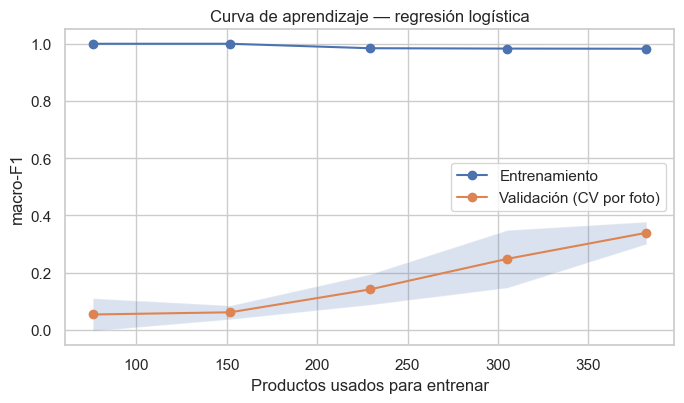

Al aumentar los datos, la validación pasa de 0.054 a 0.339 y todavía sube en el último tramo.


In [14]:
cv_all = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
rows = []
for name, mk in [("Regresión logística (baseline)", make_lr), ("Bosque aleatorio", make_rf)]:
    s = cross_val_score(mk(), X, y, groups=groups, cv=cv_all, scoring=macro_f1_scorer)
    rows.append({"modelo": name, "macroF1_train": res.loc[name, "macro_f1_train"], "macroF1_CV5_todo": s.mean(), "desv_CV": s.std(),
                 "macroF1_prueba": res.loc[name, "macro_f1_test"], "brecha_train-prueba": res.loc[name, "macro_f1_train"] - res.loc[name, "macro_f1_test"]})
gap = pd.DataFrame(rows).set_index("modelo"); display(gap.round(3))

sizes, tr_lc, va_lc = learning_curve(make_lr(), Xtr, ytr, groups=gtr, cv=cv, scoring=macro_f1_scorer,
                                     train_sizes=np.linspace(0.2, 1.0, 5), shuffle=False)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(sizes, tr_lc.mean(1), "o-", label="Entrenamiento"); ax.plot(sizes, va_lc.mean(1), "o-", label="Validación (CV por foto)")
ax.fill_between(sizes, va_lc.mean(1) - va_lc.std(1), va_lc.mean(1) + va_lc.std(1), alpha=0.2)
ax.set_xlabel("Productos usados para entrenar"); ax.set_ylabel("macro-F1"); ax.set_title("Curva de aprendizaje — regresión logística"); ax.legend()
fig.tight_layout(); plt.show()
print(f"Al aumentar los datos, la validación pasa de {va_lc.mean(1)[0]:.3f} a {va_lc.mean(1)[-1]:.3f} y todavía {'sube' if va_lc.mean(1)[-1] > va_lc.mean(1)[-2] else 'se aplana'} en el último tramo.")

## 9. Importancia y selección de características

Se aplican tres familias de métodos, siempre calculadas **solo con entrenamiento** para evitar fuga de información:

- **Filtro** (independiente del modelo): estadístico F de ANOVA e información mutua frente a la clase.
- **Embebido**: importancia por impureza del bosque aleatorio.
- **Envoltura**: eliminación recursiva de características (RFE) con la regresión logística.
- Además, **importancia por permutación** en prueba (agrupada por familia de características) y **PCA** como extracción.

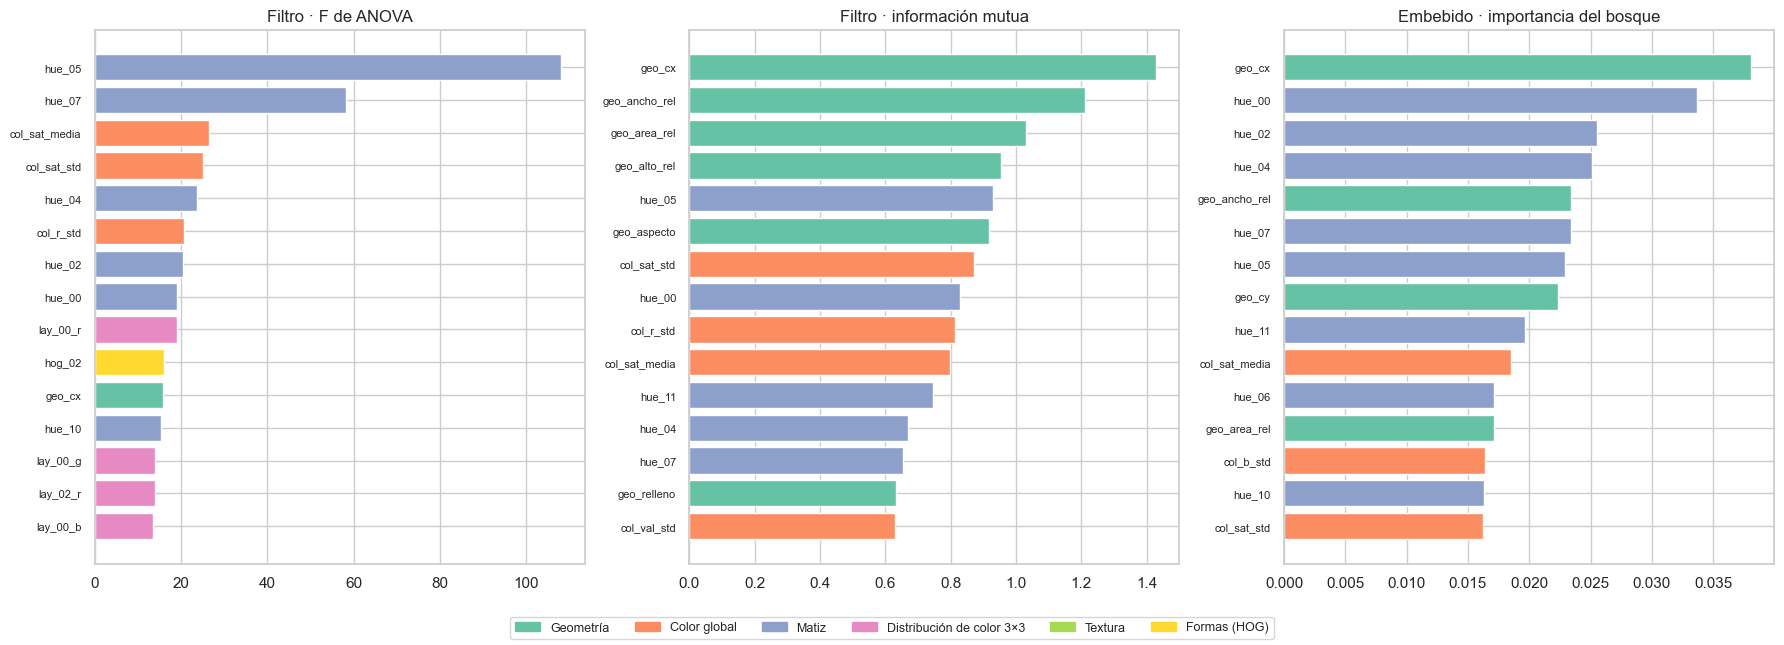

,ANOVA F (media),Info. mutua (media),Importancia bosque (suma)
Formas (HOG),6.635,0.399,0.247
Distribución de color 3×3,8.682,0.393,0.239
Matiz,24.310,0.603,0.238
Geometría,10.585,0.932,0.130
Color global,12.900,0.558,0.115
Textura,7.229,0.407,0.031


In [15]:
Xs = StandardScaler().fit(Xtr).transform(Xtr)
anova_f = pd.Series(f_classif(Xtr, ytr)[0], index=FEATURES).fillna(0)
mi = pd.Series(mutual_info_classif(Xtr, ytr, random_state=SEED), index=FEATURES)
rf_full = make_rf().fit(Xtr, ytr); rf_imp = pd.Series(rf_full.feature_importances_, index=FEATURES)
group_palette = dict(zip(FEATURE_GROUPS.values(), sns.color_palette("Set2", len(FEATURE_GROUPS))))

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, (title, s) in zip(axes, [("Filtro · F de ANOVA", anova_f), ("Filtro · información mutua", mi), ("Embebido · importancia del bosque", rf_imp)]):
    top = s.sort_values(ascending=False).head(15)[::-1]
    ax.barh(top.index, top.values, color=[group_palette[GROUP_OF[c]] for c in top.index]); ax.set_title(title); ax.tick_params(axis="y", labelsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_palette.values()]
fig.legend(handles, group_palette.keys(), loc="lower center", ncol=6, fontsize=9); fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

by_group = pd.DataFrame({"ANOVA F (media)": anova_f.groupby(GROUP_OF).mean(), "Info. mutua (media)": mi.groupby(GROUP_OF).mean(),
                         "Importancia bosque (suma)": rf_imp.groupby(GROUP_OF).sum()})
display(by_group.sort_values("Importancia bosque (suma)", ascending=False).round(3))

RFE terminó en 7 s. Características por grupo entre las 30 elegidas:


,seleccionadas
Matiz,9
Formas (HOG),8
Distribución de color 3×3,6
Geometría,4
Color global,3


,grupo,caída_macroF1,desv
0,Matiz,0.119,0.013
1,Distribución de color 3×3,0.027,0.013
2,Color global,0.020,0.011
3,Textura,0.004,0.011
4,Formas (HOG),-0.000,0.017
5,Geometría,-0.005,0.013


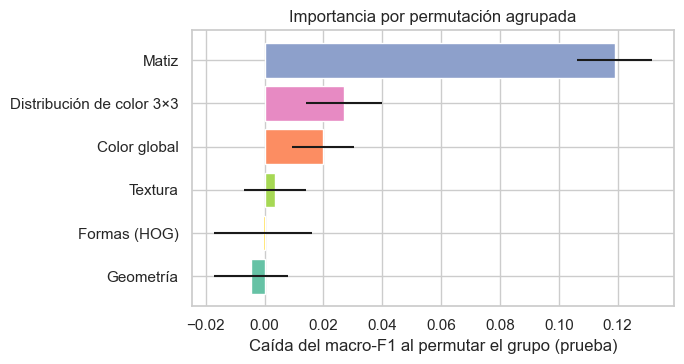

In [16]:
# Envoltura: RFE con regresión logística (92 → 30 características).
t0 = time.time()
rfe = RFE(LogisticRegression(C=BEST_C, class_weight="balanced", max_iter=2000), n_features_to_select=30, step=10).fit(Xs, ytr)
rfe_selected = [f for f, keep in zip(FEATURES, rfe.support_) if keep]
print(f"RFE terminó en {time.time() - t0:.0f} s. Características por grupo entre las 30 elegidas:")
display(pd.Series([GROUP_OF[f] for f in rfe_selected]).value_counts().rename("seleccionadas").to_frame())

# Importancia por permutación AGRUPADA en prueba: ¿cuánto cae el macro-F1 si se destruye la información de un grupo?
final_lr = models["Regresión logística (baseline)"]; base_f1 = macro_f1(yte, final_lr.predict(Xte))
rng = np.random.default_rng(SEED); perm_rows = []
for g in FEATURE_GROUPS.values():
    cols = [i for i, f in enumerate(FEATURES) if GROUP_OF[f] == g]; drops = []
    for _ in range(20):
        Xp = Xte.copy(); Xp[:, cols] = Xte[rng.permutation(len(Xte))][:, cols]
        drops.append(base_f1 - macro_f1(yte, final_lr.predict(Xp)))
    perm_rows.append({"grupo": g, "caída_macroF1": np.mean(drops), "desv": np.std(drops)})
perm = pd.DataFrame(perm_rows).sort_values("caída_macroF1", ascending=False).reset_index(drop=True)
display(perm.round(3))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(perm.grupo[::-1], perm.caída_macroF1[::-1], xerr=perm.desv[::-1], color=[group_palette[g] for g in perm.grupo[::-1]])
ax.set_xlabel("Caída del macro-F1 al permutar el grupo (prueba)"); ax.set_title("Importancia por permutación agrupada"); fig.tight_layout(); plt.show()

,macroF1_CV,desv
configuración,,
Todas (92),0.338,0.034
Filtro ANOVA · mejores 30,0.271,0.018
Embebido bosque · mejores 30,0.305,0.043
Envoltura RFE · 30,0.286,0.048
PCA (90 % de varianza),0.312,0.015
"Sin posición en la foto (geo_cx, geo_cy) (90)",0.325,0.038
Sin HOG ni geometría (53),0.317,0.049


38 s


,n,solo_este_grupo,sin_este_grupo,aporte
grupo,,,,
Matiz,12,0.292,0.169,0.170
Color global,10,0.120,0.326,0.012
Formas (HOG),32,0.100,0.349,-0.011
Distribución de color 3×3,27,0.087,0.321,0.017
Geometría,7,0.067,0.304,0.034
Textura,4,0.049,0.329,0.010


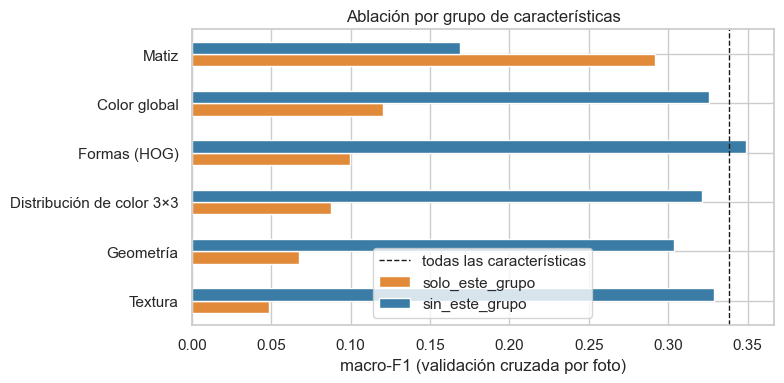

In [17]:
# ¿Ayuda quitar características? Todo el procesamiento ocurre DENTRO de cada pliegue (sin fuga).
t0 = time.time()
lr = lambda: LogisticRegression(C=BEST_C, class_weight="balanced", max_iter=2000)
configs = {
    "Todas (92)": make_pipeline(StandardScaler(), lr()),
    "Filtro ANOVA · mejores 30": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=30), lr()),
    "Embebido bosque · mejores 30": make_pipeline(StandardScaler(), SelectFromModel(RandomForestClassifier(150, random_state=SEED, n_jobs=-1), max_features=30, threshold=-np.inf), lr()),
    "Envoltura RFE · 30": make_pipeline(StandardScaler(), RFE(lr(), n_features_to_select=30, step=10), lr()),
    "PCA (90 % de varianza)": make_pipeline(StandardScaler(), PCA(n_components=0.90, svd_solver="full"), lr()),
}
sel_rows = []
for name, pipe in configs.items():
    s = cross_val_score(pipe, Xtr, ytr, groups=gtr, cv=cv, scoring=macro_f1_scorer)
    sel_rows.append({"configuración": name, "macroF1_CV": s.mean(), "desv": s.std()})
for label, drop in [("Sin posición en la foto (geo_cx, geo_cy)", lambda f: f in ("geo_cx", "geo_cy")),
                    ("Sin HOG ni geometría", lambda f: GROUP_OF[f] in ("Formas (HOG)", "Geometría"))]:
    keep_cols = [i for i, f in enumerate(FEATURES) if not drop(f)]
    s = cross_val_score(make_lr(), Xtr[:, keep_cols], ytr, groups=gtr, cv=cv, scoring=macro_f1_scorer)
    sel_rows.append({"configuración": f"{label} ({len(keep_cols)})", "macroF1_CV": s.mean(), "desv": s.std()})
sel = pd.DataFrame(sel_rows).set_index("configuración"); display(sel.round(3)); print(f"{time.time() - t0:.0f} s")

# Ablación por grupo: solo ese grupo vs. todo menos ese grupo.
abl_rows = []
for g in FEATURE_GROUPS.values():
    cols = [i for i, f in enumerate(FEATURES) if GROUP_OF[f] == g]; rest = [i for i in range(len(FEATURES)) if i not in cols]
    only = cross_val_score(make_lr(), Xtr[:, cols], ytr, groups=gtr, cv=cv, scoring=macro_f1_scorer).mean()
    without = cross_val_score(make_lr(), Xtr[:, rest], ytr, groups=gtr, cv=cv, scoring=macro_f1_scorer).mean()
    abl_rows.append({"grupo": g, "n": len(cols), "solo_este_grupo": only, "sin_este_grupo": without})
abl = pd.DataFrame(abl_rows).set_index("grupo"); abl["aporte"] = sel.loc["Todas (92)", "macroF1_CV"] - abl.sin_este_grupo
display(abl.sort_values("solo_este_grupo", ascending=False).round(3))
fig, ax = plt.subplots(figsize=(8, 4))
abl.sort_values("solo_este_grupo")[["solo_este_grupo", "sin_este_grupo"]].plot.barh(ax=ax, color=["#e08a3a", "#3a7ca5"])
ax.axvline(sel.loc["Todas (92)", "macroF1_CV"], color="k", ls="--", lw=1, label="todas las características")
ax.set_xlabel("macro-F1 (validación cruzada por foto)"); ax.set_ylabel(""); ax.set_title("Ablación por grupo de características"); ax.legend(); fig.tight_layout(); plt.show()

Componentes para explicar ≥ 90 % de la varianza: 28 de 92 | PC1 = 23.3%, PC2 = 14.8%


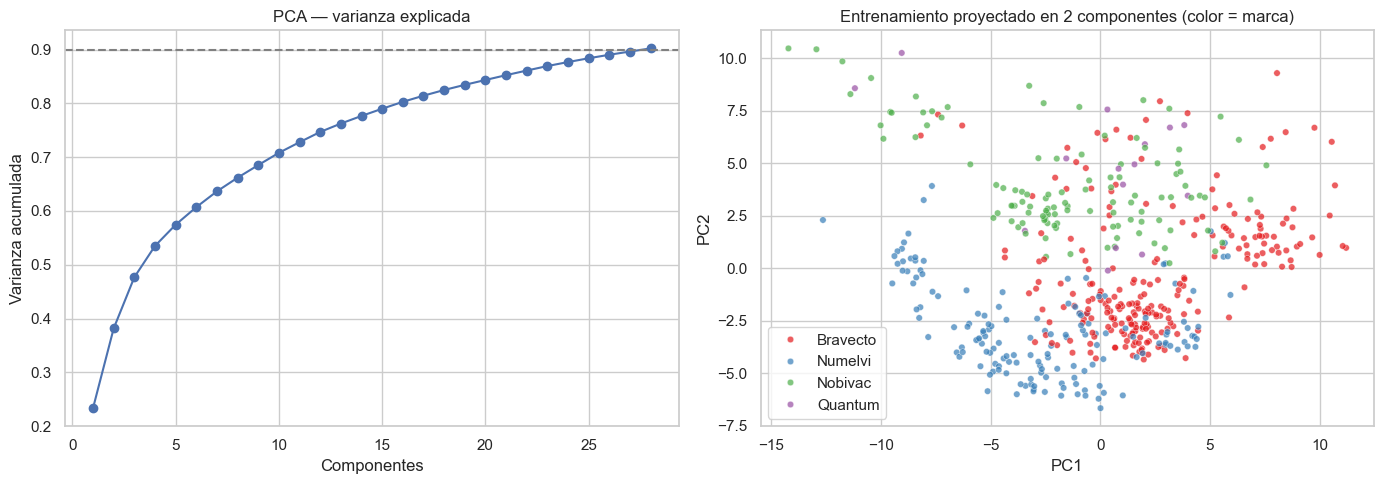

In [18]:
# PCA como extracción: ¿cuántas dimensiones realmente hay? ¿separa productos?
pca = PCA(n_components=0.90, svd_solver="full", random_state=SEED).fit(Xs); Z = PCA(n_components=2, random_state=SEED).fit_transform(Xs)
print(f"Componentes para explicar ≥ 90 % de la varianza: {pca.n_components_} de {len(FEATURES)} | PC1 = {pca.explained_variance_ratio_[0]:.1%}, PC2 = {pca.explained_variance_ratio_[1]:.1%}")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(np.arange(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), "o-")
axes[0].axhline(0.9, ls="--", color="gray"); axes[0].set_xlabel("Componentes"); axes[0].set_ylabel("Varianza acumulada"); axes[0].set_title("PCA — varianza explicada")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=[marca(c) for c in ytr], s=22, ax=axes[1], palette="Set1", alpha=0.7)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("Entrenamiento proyectado en 2 componentes (color = marca)")
fig.tight_layout(); plt.show()

## 10. Del clasificador al conteo (caso de uso)

El sistema final entrega **cuántas piezas de cada producto hay en la foto**. Aquí se mide ese efecto con la regresión logística sobre las fotos de prueba, **suponiendo que las cajas ya están localizadas** (los polígonos reales): el error de conteo es consecuencia únicamente de confundir productos. Se compara contra un baseline trivial para la etapa de localización: predecir siempre la mediana de cajas por foto del entrenamiento.

Conteo por (foto, producto): error absoluto medio = 3.04 piezas | conteos exactos = 9.3% (7 de 75)
Piezas mal asignadas por foto (media): 11.4 de 16.1 productos por foto
Baseline de localización (mediana de 7 cajas por foto): error absoluto medio = 11.9 cajas por foto (las fotos de prueba tienen entre 1 y 48)


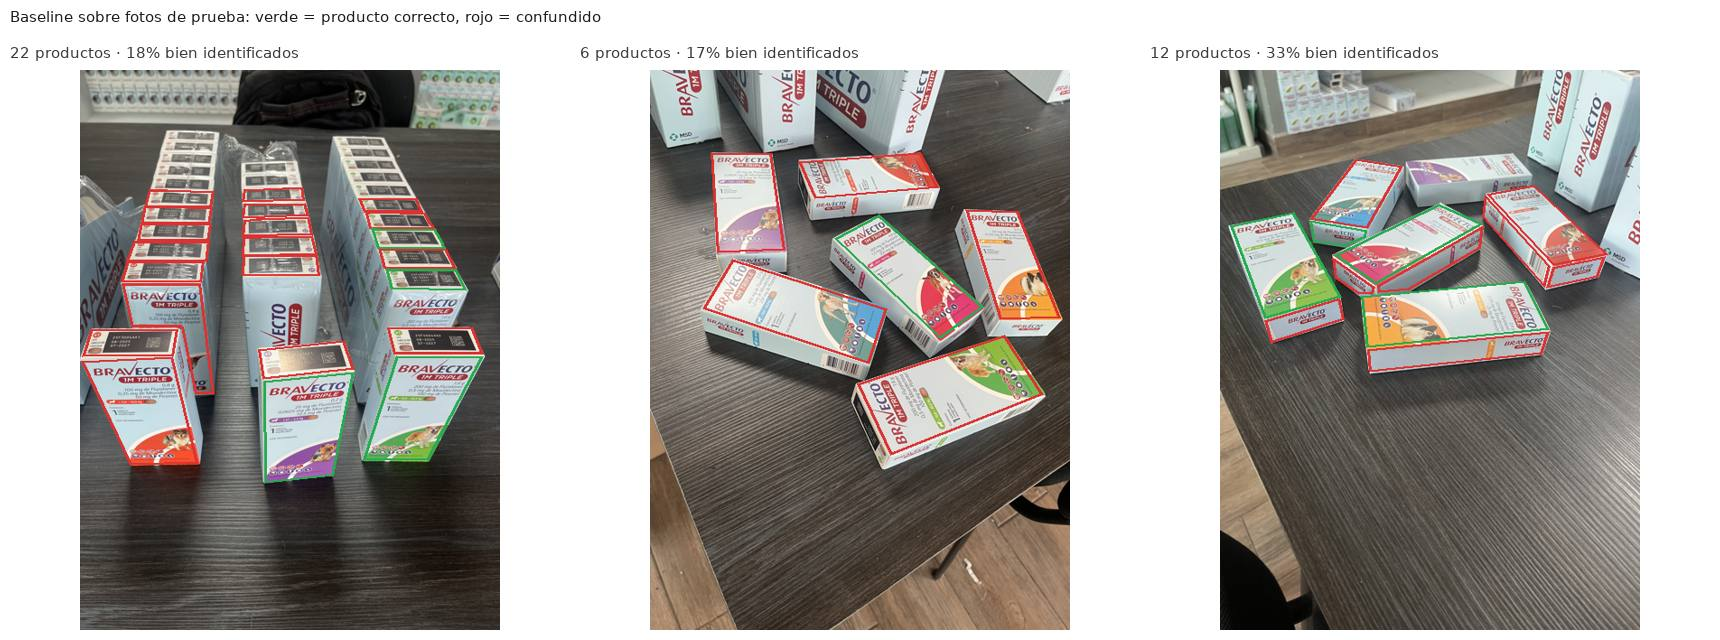

In [19]:
test_df = df.iloc[test_idx].assign(pred=best)
cnt = []
for foto, g in test_df.groupby("foto"):
    real, pred = Counter(g.clase), Counter(g.pred)
    for cls in set(real) | set(pred):
        cnt.append({"foto": foto, "clase": cls, "real": real[cls], "predicho": pred[cls]})
cnt = pd.DataFrame(cnt); cnt["error_abs"] = (cnt.real - cnt.predicho).abs()
n_pairs = len(cnt)
mae_cls = cnt.error_abs.mean(); exact = (cnt.error_abs == 0).mean()
print(f"Conteo por (foto, producto): error absoluto medio = {mae_cls:.2f} piezas | conteos exactos = {exact:.1%} ({(cnt.error_abs == 0).sum()} de {n_pairs})")
tot_err = (cnt.groupby("foto").error_abs.sum() / 2)
print(f"Piezas mal asignadas por foto (media): {tot_err.mean():.1f} de {test_df.groupby('foto').size().mean():.1f} productos por foto")

n_train_boxes = df.iloc[train_idx].groupby("foto").size(); n_test_boxes = test_df.groupby("foto").size()
dummy_count = n_train_boxes.median()
mae_boxes_dummy = (n_test_boxes - dummy_count).abs().mean()
print(f"Baseline de localización (mediana de {dummy_count:.0f} cajas por foto): error absoluto medio = {mae_boxes_dummy:.1f} cajas por foto "
      f"(las fotos de prueba tienen entre {n_test_boxes.min()} y {n_test_boxes.max()})")

# Imágenes de referencia anotadas: aciertos (verde) y errores (rojo) del baseline sobre fotos de prueba.
def draw_predictions(photo_name, max_side=620):
    with Image.open(PHOTO_PATH[photo_name]) as src:
        im = ImageOps.exif_transpose(src).convert("RGB")
    im.thumbnail((max_side, max_side)); W, H = im.size; d = ImageDraw.Draw(im)
    rows_ = test_df[test_df.foto == photo_name]
    for idx, r in rows_.iterrows():
        pts = [(x * W / 100, y * H / 100) for x, y in POLYS[idx]]
        d.polygon(pts, outline=(40, 170, 80) if r.clase == r.pred else (220, 50, 50), width=3)
    return im, (rows_.clase == rows_.pred).mean(), len(rows_)

cands = n_test_boxes[(n_test_boxes >= 6) & (n_test_boxes <= 25)].index.tolist()[:3]
if cands:
    shots = [draw_predictions(name) for name in cands]
    show_mosaic([s[0] for s in shots], [f"{s[2]} productos · {s[1]:.0%} bien identificados" for s in shots], cols=len(cands), cell=560,
                title="Baseline sobre fotos de prueba: verde = producto correcto, rojo = confundido")

## 11. Desempeño mínimo esperado

**No existe un sistema previo ni un conteo histórico medido**, así que no hay un desempeño "histórico" contra el cual comparar. El piso se define entonces con referencias triviales y se propone, como hipótesis de trabajo a validar con Vetlife, una meta de negocio:

| Nivel | Definición | Origen |
|---|---|---|
| **Piso (hay señal en los datos)** | superar al mejor modelo trivial por al menos 0.10 de macro-F1 | si no, los datos/características no contienen información útil |
| **Mínimo aceptable (baseline)** | macro-F1 por encima del piso con un modelo simple y explicable | punto de partida para comparar mejoras |
| **Meta propuesta del proyecto** | macro-F1 ≥ 0.80 y ≥ 90 % de conteos por producto exactos | *supuesto del equipo*; se debe confirmar con el cliente según el costo de un error |

In [20]:
best_trivial = max(res.loc["Dummy · clase mayoritaria", "macro_f1_test"], np.mean(rand_f1))
lr_row = res.loc["Regresión logística (baseline)"]
lr_cv_mean = gap.loc["Regresión logística (baseline)", "macroF1_CV5_todo"]
check = pd.DataFrame([
    {"criterio": "Piso · macro-F1 en prueba fija vs. mejor trivial (+0.10)", "valor": lr_row.macro_f1_test, "umbral": best_trivial + 0.10, "cumple": lr_row.macro_f1_test >= best_trivial + 0.10},
    {"criterio": "Piso · macro-F1 en validación cruzada (5 pliegues) vs. mejor trivial (+0.10)", "valor": lr_cv_mean, "umbral": best_trivial + 0.10, "cumple": lr_cv_mean >= best_trivial + 0.10},
    {"criterio": "accuracy vs. azar uniforme (1/clases)", "valor": lr_row.accuracy_test, "umbral": 1 / len(set(ytr)), "cumple": lr_row.accuracy_test > 1 / len(set(ytr))},
    {"criterio": "Meta del proyecto: macro-F1 ≥ 0.80 (validación cruzada)", "valor": lr_cv_mean, "umbral": 0.80, "cumple": lr_cv_mean >= 0.80},
    {"criterio": "Meta del proyecto: conteos por producto exactos ≥ 90 %", "valor": exact, "umbral": 0.90, "cumple": exact >= 0.90},
]).set_index("criterio")
display(check.round(3))

,valor,umbral,cumple
criterio,,,
Piso · macro-F1 en prueba fija vs. mejor trivial (+0.10),0.169,0.117,True
Piso · macro-F1 en validación cruzada (5 pliegues) vs. mejor trivial (+0.10),0.349,0.117,True
accuracy vs. azar uniforme (1/clases),0.255,0.024,True
Meta del proyecto: macro-F1 ≥ 0.80 (validación cruzada),0.349,0.800,False
Meta del proyecto: conteos por producto exactos ≥ 90 %,0.093,0.900,False


## 12. Conclusiones

La celda siguiente imprime las cifras calculadas en esta ejecución; el texto posterior las interpreta.

In [21]:
lr_cv = gap.loc["Regresión logística (baseline)"]; rf_row = res.loc["Bosque aleatorio"]
top_group = perm.iloc[0]; top_solo = abl.solo_este_grupo.idxmax()
print("RESUMEN — BASELINE")
print(f"- Datos: {len(df)} productos en {df.foto.nunique()} fotos, {df.clase.nunique()} clases (mediana {counts.median():.0f} ejemplos por clase; {(counts < 5).sum()} clases con < 5).")
print(f"- Piso: clase mayoritaria macro-F1 {res.loc['Dummy · clase mayoritaria', 'macro_f1_test']:.3f} (accuracy {res.loc['Dummy · clase mayoritaria', 'accuracy_test']:.3f}); azar estratificado macro-F1 {np.mean(rand_f1):.3f}.")
print(f"- Baseline (regresión logística, C={BEST_C}): macro-F1 {lr_row.macro_f1_test:.3f}, accuracy {lr_row.accuracy_test:.3f}, balanced accuracy {lr_row.balanced_acc_test:.3f}, top-3 {lr_row.top3_acc_test:.3f}, línea correcta {lr_row.acc_linea_test:.1%}.")
print(f"- Bosque aleatorio: macro-F1 {rf_row.macro_f1_test:.3f}, accuracy {rf_row.accuracy_test:.3f}.")
print(f"- Sobreajuste: macro-F1 entrenamiento {lr_cv.macroF1_train:.3f} vs. CV {lr_cv.macroF1_CV5_todo:.3f} ± {lr_cv.desv_CV:.3f} vs. prueba {lr_cv.macroF1_prueba:.3f} (brecha {lr_cv['brecha_train-prueba']:.3f}).")
print(f"- Características: el grupo con mayor caída al permutarlo es '{top_group.grupo}' (−{top_group.caída_macroF1:.3f} de macro-F1); el que mejor funciona solo es '{top_solo}'.")
print(f"- Selección: macro-F1 CV con las 92 = {sel.loc['Todas (92)', 'macroF1_CV']:.3f}; mejor configuración reducida = {sel.drop('Todas (92)').macroF1_CV.idxmax()} ({sel.drop('Todas (92)').macroF1_CV.max():.3f}).")
print(f"- Conteo con cajas conocidas: error medio {mae_cls:.2f} piezas por (foto, producto); {exact:.1%} exactos. Baseline de localización: error medio {mae_boxes_dummy:.1f} cajas por foto.")
print(f"- Errores dentro de la misma línea de producto: {conf.misma_linea.mean():.1%}.")
print(f"- Nivel de identificación en validación cruzada: marca {where.ok_marca.mean():.1%}, línea {where.ok_linea.mean():.1%}, producto exacto {where.ok_producto.mean():.1%}.")
print("- Producto exacto por cara anotada: " + "; ".join(f"{k}: {v:.1%} (n={int(n)})" for k, v, n in zip(resumen_cara.index, resumen_cara.producto_exacto, resumen_cara.productos)) + ".")
print(f"- Posición en la foto (geo_cx, geo_cy): macro-F1 CV sin ellas = {sel.loc[[i for i in sel.index if i.startswith('Sin posición')][0], 'macroF1_CV']:.3f} vs. {sel.loc['Todas (92)', 'macroF1_CV']:.3f} con todas.")

RESUMEN — BASELINE
- Datos: 676 productos en 44 fotos, 44 clases (mediana 12 ejemplos por clase; 9 clases con < 5).
- Piso: clase mayoritaria macro-F1 0.000 (accuracy 0.006); azar estratificado macro-F1 0.017.
- Baseline (regresión logística, C=0.3): macro-F1 0.169, accuracy 0.255, balanced accuracy 0.173, top-3 0.404, línea correcta 56.5%.
- Bosque aleatorio: macro-F1 0.173, accuracy 0.242.
- Sobreajuste: macro-F1 entrenamiento 0.974 vs. CV 0.349 ± 0.067 vs. prueba 0.169 (brecha 0.805).
- Características: el grupo con mayor caída al permutarlo es 'Matiz' (−0.119 de macro-F1); el que mejor funciona solo es 'Matiz'.
- Selección: macro-F1 CV con las 92 = 0.338; mejor configuración reducida = Sin posición en la foto (geo_cx, geo_cy) (90) (0.325).
- Conteo con cajas conocidas: error medio 3.04 piezas por (foto, producto); 9.3% exactos. Baseline de localización: error medio 11.9 cajas por foto.
- Errores dentro de la misma línea de producto: 41.7%.
- Nivel de identificación en validación cr

### 12.1 Respuestas a las preguntas guía

**¿Qué algoritmo sirve como baseline?** Una **regresión logística multinomial** estandarizada y regularizada (C = 0.3, elegido con validación cruzada por foto y la regla de un error estándar), acompañada de dos referencias triviales (clase mayoritaria y azar estratificado) y un bosque aleatorio de contraste. Es adecuada porque el problema es de clasificación multiclase sobre pocas filas (676) con muchas variables (92), donde un modelo lineal regularizado e interpretable es el punto de partida estándar. Con macro-F1 de prueba de 0.169 y de 0.349 ± 0.067 en validación cruzada, supera con claridad al azar (0.017); el bosque aleatorio, un modelo muy distinto, rinde parecido (0.173 en prueba y 0.364 ± 0.089 en validación cruzada). Que dos algoritmos tan diferentes lleguen al mismo nivel sugiere que el límite lo pone **la información de las características**, no el algoritmo.

**¿Qué características importan?** El **histograma de matiz (color)** domina: con solo esas 12 variables la validación cruzada alcanza 0.292 de macro-F1 (con las 92, 0.338); sin ellas cae a 0.169, y permutarlas en prueba reduce el macro-F1 en 0.119. Textura, formas HOG y geometría no aportan de forma distinguible del ruido (permutar HOG o geometría no empeora la prueba). Ninguna reducción superó a usar las 92 (ANOVA 0.271, bosque 0.305, RFE 0.286, PCA 0.312, sin posición 0.325, sin HOG ni geometría 0.317 frente a 0.338; varias diferencias caen dentro de una desviación estándar de ≈ 0.03–0.05) y el PCA necesita 28 componentes para explicar 90 % de la varianza, así que hay poca redundancia que comprimir. Para este baseline se conservan las 92 variables; la mejora de fondo no vendrá de seleccionar, sino de características que "lean" el empaque (texto y diseño).

**¿Hay sub o sobreajuste?** Hay **sobreajuste** (varianza alta), no subajuste: macro-F1 de 0.974 en entrenamiento contra 0.349 en validación cruzada y 0.169 en la prueba fija. La curva de validación muestra el entrenamiento llegando a ≈ 1 mientras la validación se estanca cerca de 0.34 para C ≥ 1; regularizar más reduce la brecha pero baja la validación (0.211 con C = 0.003), así que no es solo cuestión de regularización. La curva de aprendizaje de la validación sube de 0.054 a 0.339 y no se aplana, lo que indica que **más etiquetas ayudarían**.

**¿Cuál es la métrica adecuada?** El **macro-F1** (cada producto pesa igual, sensible al desbalance), complementado con la exactitud por nivel (marca, línea, producto exacto) para distinguir errores cercanos de graves, y con el **error de conteo** por foto y producto, que es lo que el cliente percibe.

**¿Cuál debería ser el desempeño mínimo?** Como no hay un sistema previo medido, el piso se fija con referencias triviales (macro-F1 ≈ 0.02) y se propone una meta de negocio como hipótesis a validar con Vetlife (macro-F1 ≥ 0.80 y ≥ 90 % de conteos exactos). El baseline **cumple el piso** (0.349 en validación cruzada y 0.169 en la prueba fija frente a un umbral de 0.117; accuracy de 0.255 frente a 0.024 del azar) y **no cumple la meta** (conteos exactos: 9.3 %). Conclusión: hay señal en los datos y el problema es viable, pero un modelo que no lee el empaque no basta para contar con la precisión que se busca.

### 12.2 Lo que aprendimos para el caso de uso

- **Se acierta la marca, no la presentación.** En validación cruzada el baseline identifica la marca el 92.5 % de las veces, la línea el 78.3 % y el producto exacto el 42.8 %. Los errores se concentran entre dosis y presentaciones de una misma línea (Bravecto), cuya diferencia está en el texto que estas características no leen. Es el hueco que debe cerrar el siguiente modelo.
- **Dos tercios de las anotaciones son franjas horizontales** (452 de 676 recortes): laterales o tapas de cajas apiladas. El baseline las identifica en proporciones similares a los frentes (producto exacto 43.8 % contra 50.6 %), por lo que no se puede afirmar que sean intrínsecamente más difíciles. Sí obliga a definir una **política de etiquetado y conteo de pilas**: contar cada franja o contar pilas y su altura.
- **Posición en la foto.** `geo_cx` y `geo_cy` figuran entre las variables más informativas según información mutua y bosque, pero quitarlas solo cambia el macro-F1 de validación de 0.338 a 0.325 (dentro del ruido); no hay evidencia de que sean un atajo ni de que ayuden.
- **El conteo sufre.** Aun con las cajas ya localizadas, el conteo por producto es exacto en solo 9.3 % de los casos (error absoluto medio de 3.04 piezas), y un localizador trivial (mediana de cajas) se equivoca por 11.9 cajas por foto: la detección tampoco es trivial.

### 12.3 Limitaciones

- La prueba fija tiene solo 10 fotos (161 productos) y 3 clases que el entrenamiento nunca vio (14 productos que nadie podría acertar); por eso su macro-F1 (0.169) es notablemente menor que el de la validación cruzada (0.349) y debe leerse como un rango, no como un valor puntual.
- Nueve clases tienen menos de cinco ejemplos y una solo uno: su métrica no es confiable.
- Las características no leen texto; los hiperparámetros se ajustaron lo mínimo; las metas de negocio son supuestos del equipo.

### 12.4 Siguientes pasos (Avance 4)

1. Entrenar una **CNN preentrenada (transfer learning)** sobre los mismos recortes y compararla con este baseline usando exactamente la misma partición (`avance3_fotos_prueba.csv`).
2. Modelo de dos etapas: **detector** de cajas (una clase) + **clasificador de recortes**; ya existe un prototipo en el proyecto, pendiente de entrenar con GPU, cuyo resultado se medirá contra estas métricas.
3. Incorporar el **texto del empaque** (dosis y número de tabletas), por ejemplo con lectura de texto sobre el frente de la caja.
4. Definir con el cliente la **política de conteo de pilas** y confirmar las metas de desempeño.
5. Priorizar nuevas etiquetas para las clases con menos de cinco ejemplos y para fotos que no estén en el conjunto actual.

## Referencias

- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media. [O'Reilly](https://learning.oreilly.com/library/view/hands-on-machine-learning/9781098125967/).
- Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., & Plöd, M. (2023). *CRISP-ML(Q): The ML Lifecycle Process*. [INNOQ](https://ml-ops.org/content/crisp-ml).
- Scikit-learn. [`StratifiedGroupKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html), [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [`RFE`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html), [`learning_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html).
- Dalal, N., & Triggs, B. (2005). Histograms of oriented gradients for human detection. *CVPR*.